In [ ]:
%matplotlib inline

# Solution 4 (optional) — Increase the IP beta functions

Increase both IP beta functions by a factor of five, from 0.09 m / 0.0008 m to 0.45 m / 0.004 m. Keep a waist at the IP: $\alpha_x=\alpha_y=0$.

Match the two halves of the straight around `ipd`, keeping the nominal optics at the outer boundaries. The quadrupole circuits are shared by the four experimental insertions, so all four IPs change together. Complete the missing code. Restore the nominal tunes and chromaticities with the arc circuits.

### Load the nominal lattice

In [1]:
import xtrack as xt

env = xt.load('fccee_z.json')
env.vars.load('optics_nominal.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)
tw0 = line.twiss4d(delta_chrom=1e-6)

### Inspect the experimental straight

In [2]:
ip = 'ipd'
start = 'end_ds_start_straight_ipd'
end = 'end_straight_start_ds_ipd'

tw0.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02473
ipd                             22665.1          0.09        0.0008  -6.72924e-09   2.38195e-08
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02472

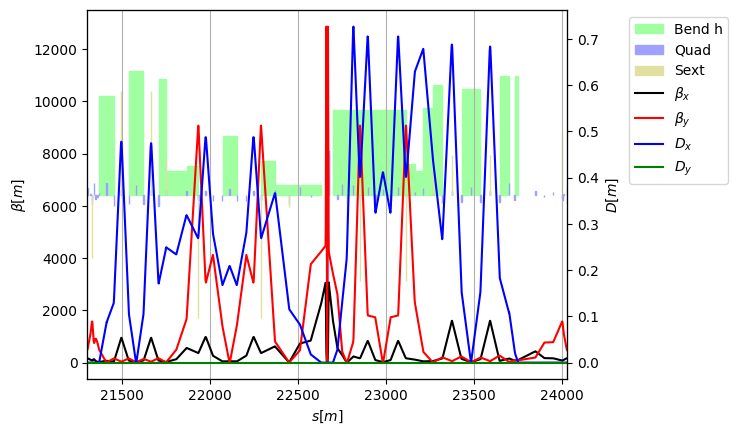

In [3]:
tw0.rows[start:end].plot()

### Quadrupoles for matching

Use the quadrupoles in the nominally dispersion-free matching sections. The supplied lattice already has independent knobs for the left and right sides. Keep the final-focus and dispersion-suppressor magnets fixed.

In [4]:
knobs_left = ['kqd16l', 'kqf17l', 'kqd18l', 'kqf19l', 'kqd20l',
              'kqd8m', 'kqf9m', 'kqd10m']
knobs_right = ['kqf17r', 'kqd18r', 'kqf19r', 'kqd20r',
               'kqd8mr', 'kqf9mr', 'kqd10mr']

### Fix the boundary optics

Use the nominal Twiss parameters at the two outer boundaries as initial conditions for open matching.

In [5]:
init_left = tw0.get_twiss_init(start)
init_right = tw0.get_twiss_init(end)

### Set the IP targets

Target five times the nominal beta functions and zero alpha in both planes. The supplied weights account for the different horizontal and vertical beta scales.

In [6]:
beta_factor = 5

targets_ip = [
    xt.Target('betx', at=ip, value=beta_factor * tw0['betx', ip], tol=1e-8, weight=10),
    xt.Target('bety', at=ip, value=beta_factor * tw0['bety', ip], tol=1e-10, weight=1000),
    xt.TargetSet(alfx=0, alfy=0, at=ip, tol=1e-7),
]

### Match the left half

Propagate from `start` to `ip` using `init_left` and vary `knobs_left`. `line.match` solves the matching problem directly.

In [7]:
opt_left = line.match(
    method='4d',
    start=start, end=ip, init=init_left,
    vary=xt.VaryList(knobs_left, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

                                             
Optimize - start penalty: 4.817                         

Optimize - end penalty:  1.38988e-08                            


In [8]:
opt_left.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx    True   6.49324e-10          0.45          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True    5.5419e-13         0.004         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -1.22582e-09  -1.22582e-09             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -6.65152e-11  -6.65152e-11             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


### Match the right half

Use the range from `ip` to `end`, with `init_right` specified at `end`. Set `init_at=end` to propagate backwards from the downstream boundary.

In [9]:
opt_right = line.match(
    method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

                                             
Optimize - start penalty: 4.817                         

Optimize - end penalty:  2.66768e-10                            


### Limit the horizontal beta peak

After matching the IP, add an `xt.LessThan(1000)` target on the maximum horizontal beta in the right half. Clone the optimizer to keep the same IP targets, quadrupoles and boundary optics, then solve again.

In [10]:
opt_right = opt_right.clone(add_targets=[
    xt.Target(lambda tw: tw.betx.max(), xt.LessThan(1000),
              tol=1e-3, weight=1e-3, tag='max_betx'),
])
opt_right.solve()

                                             
Optimize - start penalty: 0.172                         

Optimize - end penalty:  5.16602e-07                            


In [11]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val target_val           description                                 
0  ON    ipd_betx    True   2.26636e-10          0.45 0.45000002105004744  ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True   1.94807e-12         0.004 0.004000000497804704 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True   1.22467e-09   1.22467e-09 0                    ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -6.49173e-13  -6.49173e-13 0                    ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
4  ON    max_betx    True  -0.000516448          1000 LessThan(1000)       callable, val=LessThan(1000), tol=0.001, ...


### Inspect the matched straight

Propagate through the entire straight from the fixed left boundary. Compare the IP beta functions and the recovered right-boundary optics with the nominal table above.

In [12]:
tw_local = line.twiss4d(start=start, end=end, init=init_left)
tw_local.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02473
ipd                             22665.1          0.45         0.004  -1.22582e-09  -6.65152e-11
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02472

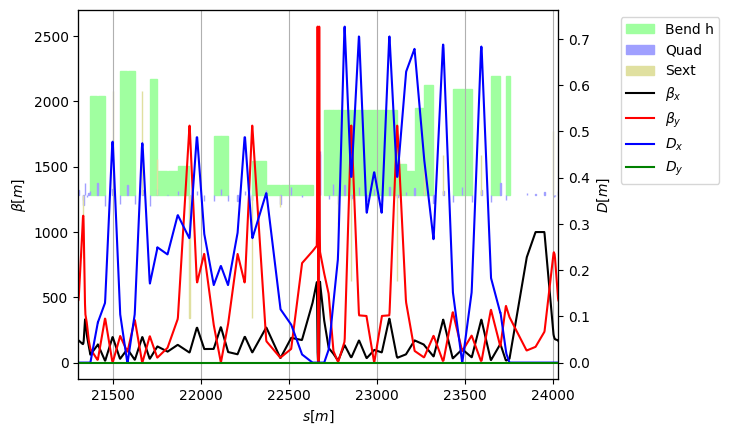

In [13]:
tw_local.plot()

### Restore the tunes

Use the arc quadrupole circuits `kqf2` and `kqd1` to recover the nominal tunes from `tw0`.

In [14]:
opt_tunes = line.match(
    method='4d',
    vary=xt.VaryList(['kqf2', 'kqd1'], step=1e-8),
    targets=xt.TargetSet(qx=tw0.qx, qy=tw0.qy, tol=1e-8),
)

                                             
Optimize - start penalty: 0.8874                         

Optimize - end penalty:  4.71829e-08                            


### Restore the chromaticities

Use the arc sextupole families `ksf1` and `ksd1` to recover the nominal chromaticities. Keep `delta_chrom=1e-6`, as in the nominal calculation.

In [15]:
opt_chroma = line.match(
    method='4d', delta_chrom=1e-6,
    vary=xt.VaryList(['ksf1', 'ksd1'], step=1e-5),
    targets=xt.TargetSet(dqx=tw0.dqx, dqy=tw0.dqy, tol=1e-3),
)

                                             
Optimize - start penalty: 27.59                         

Optimize - end penalty:  0.000152525                            


### Check the periodic ring

Recalculate the periodic optics and check all four IPs, tunes, and chromaticities. The arc quadrupole adjustment can slightly change the IP beta functions.

In [16]:
tw = line.twiss4d(delta_chrom=1e-6)
tw.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['betx bety alfx alfy']

TwissTable: 4 rows, 5 cols
name          betx          bety          alfx          alfy
ipa       0.449987     0.0039977  -4.08945e-06    6.1799e-05
ipd       0.449987     0.0039977  -4.08549e-06   6.18094e-05
ipg       0.449987     0.0039977   -4.0793e-06   6.18461e-05
ipj       0.449987     0.0039977  -4.10785e-06   6.18411e-05

In [17]:
print('Nominal tunes:', tw0.qx, tw0.qy)
print('Larger IP beta tunes:', tw.qx, tw.qy)

Nominal tunes: 166.15999999717738 162.20000000587538
Larger IP beta tunes: 166.16000000189612 162.2000000059899


In [18]:
print('Nominal chromaticities:', tw0.dqx, tw0.dqy)
print('Larger IP beta chromaticities:', tw.dqx, tw.dqy)
print('Maximum horizontal beta in right half [m]:', tw.rows[ip:end].betx.max())

Nominal chromaticities: 6.480135212960839 7.810249073901525
Larger IP beta chromaticities: 6.479982687857168 7.81024905969067
Maximum horizontal beta in right half [m]: 999.9723253707856
